# 第二章实验：神经语言模型的前向计算

**Token IDs → embedding → 拼接 → MLP → logits → softmax**。

使用 6 个 token、2 个历史位置、2 维 embedding 和 3 维隐藏层。固定的 51 个参数用于逐项核对计算；训练将在后续实验展开。

[第二章正文](../../docs/02-neural-language-models.md) · [实验说明](README.md)

## 1. 导入与词表

Token ID 用于查表，数字本身不表示词义。图中用 ID 标记 token，下面的表给出对应关系。

In [1]:
from pathlib import Path
import os
import sys

# 从仓库根目录或实验目录启动 Notebook 都可以。
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "docs/00-learning-path.md").exists())
CACHE = ROOT / "experiments/.cache"
CACHE.mkdir(exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(CACHE / "matplotlib"))
os.environ.setdefault("XDG_CACHE_HOME", str(CACHE))

import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "font.family": "DejaVu Sans",
                     "axes.spines.top": False, "axes.spines.right": False})

sys.path.insert(0, str(ROOT / "experiments/02-neural-lm"))
from forward import TOKENS, E, W1, B1, W2, B2, forward, parameter_count
np.set_printoptions(precision=5, suppress=True)
display(Markdown("| ID | Token |\n|---|---|\n" + "\n".join(
    f"| {i} | {word} |" for i, word in enumerate(TOKENS))))
contexts = np.array([[0, 2], [1, 2], [0, 3]])  # 我喜欢、你喜欢、我研究
print("输入 IDs，形状", contexts.shape)
print(contexts)

| ID | Token |
|---|---|
| 0 | 我 |
| 1 | 你 |
| 2 | 喜欢 |
| 3 | 研究 |
| 4 | 数学 |
| 5 | 物理 |

输入 IDs，形状 (3, 2)
[[0 2]
 [1 2]
 [0 3]]


## 2. Embedding 是共享的查找表

$$E\in\mathbb R^{V\times d},\qquad e_i=E_{i,:}.$$

同一 token 在不同样本、不同位置使用相同的一行。索引查表与 one-hot 乘矩阵等价。

Embedding 矩阵 E：
[[1.  0. ]
 [0.8 0.2]
 [0.  1. ]
 [0.2 0.9]
 [0.6 0.7]
 [0.5 0.8]]
查表后形状： (3, 2, 2)
[[[1.  0. ]
  [0.  1. ]]

 [[0.8 0.2]
  [0.  1. ]]

 [[1.  0. ]
  [0.2 0.9]]]


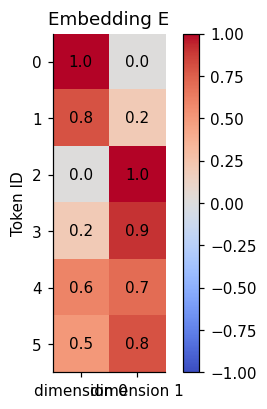

In [2]:
print("Embedding 矩阵 E：")
print(E)
embedded = E[contexts]
print("查表后形状：", embedded.shape)
print(embedded)
one_hot = np.eye(len(TOKENS))[contexts]
np.testing.assert_allclose(one_hot @ E, embedded)
fig, ax = plt.subplots(figsize=(4, 4))
im = ax.imshow(E, cmap="coolwarm", vmin=-1, vmax=1)
ax.set(xticks=[0,1], xticklabels=["dimension 0", "dimension 1"],
       yticks=range(len(TOKENS)), yticklabels=range(len(TOKENS)), ylabel="Token ID", title="Embedding E")
for i in range(len(TOKENS)):
    for j in range(2):
        ax.text(j,i,f"{E[i,j]:.1f}",ha="center",va="center")
fig.colorbar(im,ax=ax)
display(fig)
plt.close(fig)

## 3. 按位置拼接，保留顺序

$$x=[e_{t-2};e_{t-1}]\in\mathbb R^{1\times4}.$$

“我 喜欢”与“喜欢 我”的 embedding 相同，但拼接顺序不同。

In [3]:
x = embedded.reshape(len(contexts), -1)
print("上下文向量形状：", x.shape)
print(x)
swapped = E[np.array([[2,0]])].reshape(1,-1)
print("喜欢 我：", swapped)
assert not np.allclose(x[0], swapped[0])

上下文向量形状： (3, 4)
[[1.  0.  0.  1. ]
 [0.8 0.2 0.  1. ]
 [1.  0.  0.2 0.9]]
喜欢 我： [[0. 1. 1. 0.]]


## 4. 共享 MLP

$$h=\tanh(xW_1+b_1),\qquad z=hW_2+b_2.$$

$W_1$ 的形状是 $4\times3$，$W_2$ 的形状是 $3\times6$。每个样本都使用相同的权重。

In [4]:
print("W1 =", W1, "\nb1 =", B1)
print("W2 =", W2, "\nb2 =", B2)
preactivation = x @ W1 + B1
hidden = np.tanh(preactivation)
logits = hidden @ W2 + B2
for name, array in [("线性结果", preactivation), ("隐藏表示", hidden), ("logits", logits)]:
    print(name, array.shape, "\n", array)
np.testing.assert_allclose(preactivation[0], [1.1, 0., 0.2], atol=1e-12)

W1 = [[ 0.5 -0.2  0.1]
 [ 0.1  0.4 -0.3]
 [-0.2  0.3  0.5]
 [ 0.6  0.1  0.2]] 
b1 = [ 0.   0.1 -0.1]
W2 = [[-0.5 -0.4  0.1  0.2  0.8  0.7]
 [ 0.2  0.1 -0.3  0.1  0.4  0.5]
 [ 0.  -0.1  0.2  0.3  0.6  0.8]] 
b2 = [-0.3 -0.3 -0.2 -0.2  0.1  0.1]
线性结果 (3, 3) 
 [[1.1  0.   0.2 ]
 [1.02 0.12 0.12]
 [1.   0.05 0.28]]
隐藏表示 (3, 3) 
 [[0.8005  0.      0.19738]
 [0.76987 0.11943 0.11943]
 [0.76159 0.04996 0.27291]]
logits (3, 6) 
 [[-0.70025 -0.63994 -0.08048  0.01931  0.85882  0.81825]
 [-0.66105 -0.60795 -0.13496  0.00174  0.83532  0.79416]
 [-0.67081 -0.62693 -0.08425  0.03919  0.893    0.87642]]


## 5. Softmax 与目标词损失

$$q_j=\frac{\exp(z_j-m)}{\sum_v\exp(z_v-m)},\qquad m=\max_v z_v.$$

平均交叉熵仍是第一章的目标 $-\frac1B\sum_b\ln q_{b,y_b}$。

概率：
 [[0.06539 0.06945 0.12152 0.13427 0.31087 0.29851]
 [0.06926 0.07304 0.11721 0.13438 0.30929 0.29682]
 [0.06514 0.06806 0.1171  0.13249 0.31116 0.30605]]
各行概率和： [1. 1. 1.]
逐样本 NLL： [1.16839 1.21464 1.16744] 平均 NLL： 1.183489861328703


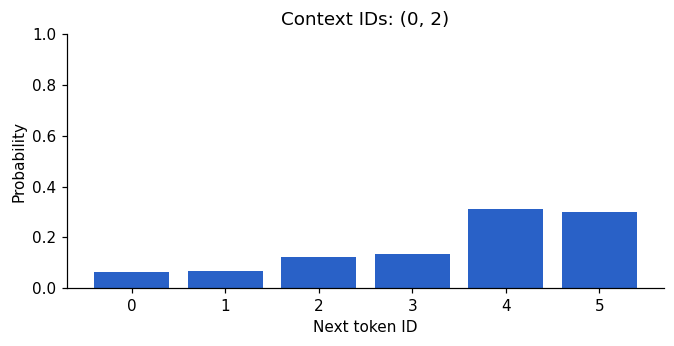

上下文： 我 喜欢
h = [0.8005 0.     0.1974]
q = [0.0654 0.0695 0.1215 0.1343 0.3109 0.2985]


In [5]:
shifted = logits - logits.max(axis=-1, keepdims=True)
log_probs = shifted - np.log(np.exp(shifted).sum(axis=-1, keepdims=True))
probs = np.exp(log_probs)
targets = np.array([4, 5, 4])  # 数学、物理、数学
nll = -log_probs[np.arange(len(contexts)), targets]
print("概率：\n", probs)
print("各行概率和：", probs.sum(axis=-1))
print("逐样本 NLL：", nll, "平均 NLL：", nll.mean())
np.testing.assert_allclose(probs.sum(axis=-1), 1.)
np.testing.assert_allclose(probs, forward(contexts)["probs"])

def draw_probabilities(first=0, second=2, like_coordinate=0.):
    result = forward([[first, second]], like_coordinate)
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.bar(range(len(TOKENS)), result["probs"][0], color="#2961c7")
    ax.set(xticks=range(len(TOKENS)), xlabel="Next token ID", ylabel="Probability",
           ylim=(0,1), title=f"Context IDs: ({first}, {second})")
    display(fig)
    plt.close(fig)
    print("上下文：", TOKENS[first], TOKENS[second])
    print("h =", np.round(result["hidden"][0], 4))
    print("q =", np.round(result["probs"][0], 4))

draw_probabilities()

## 6. 修改共享参数会影响哪些样本？

改变 `E[喜欢, 0]`，观察三个固定上下文对“数学”的预测。包含“喜欢”的两个上下文会使用同一行被修改的向量；“我 研究”的输入向量保持不变。

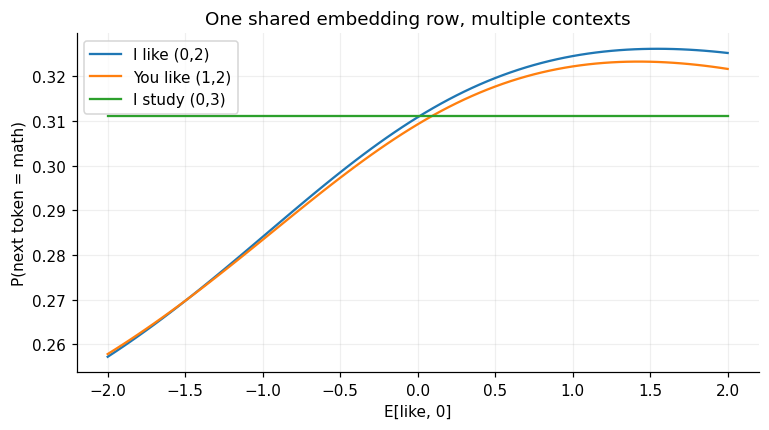

参数总数： 51


In [6]:
coordinates = np.linspace(-2, 2, 81)
curves = np.array([forward(contexts, value)["probs"][:, 4] for value in coordinates])
fig, ax = plt.subplots(figsize=(8, 4))
for i, label in enumerate(["I like (0,2)", "You like (1,2)", "I study (0,3)"]):
    ax.plot(coordinates, curves[:,i], label=label)
ax.set(xlabel="E[like, 0]", ylabel="P(next token = math)", title="One shared embedding row, multiple contexts")
ax.legend()
ax.grid(alpha=0.2)
display(fig)
plt.close(fig)
np.testing.assert_allclose(curves[:,2], curves[0,2])
print("参数总数：", parameter_count())
assert parameter_count() == 6*2 + 4*3 + 3 + 3*6 + 6 == 51

## 7. 交互前向计算

选择两个输入 token，或拖动“喜欢”的第一维坐标。隐藏层与下一 token 的分布会一起变化。

In [7]:
import ipywidgets as widgets
options = [(f"{i}: {word}", i) for i, word in enumerate(TOKENS)]
first = widgets.Dropdown(options=options, value=0, description="位置 1")
second = widgets.Dropdown(options=options, value=2, description="位置 2")
coordinate = widgets.FloatSlider(min=-2,max=2,step=0.1,value=0,description="喜欢[0]",continuous_update=False)
output = widgets.interactive_output(draw_probabilities,
                                    {"first": first, "second": second, "like_coordinate": coordinate})
display(widgets.VBox([widgets.HBox([first, second]), coordinate, output]))

## 小结与下一步

模型用同一组 embedding 和网络权重处理所有上下文；拼接保留顺序，softmax 产生概率，交叉熵评价预测。

接下来推导交叉熵如何对 logits、网络权重和 embedding 求导，让这些参数由训练数据更新。